# 03 · Building the West Africa dataset

Same features, same source, same code path as Taiwan — that is the entire point.
Any difference in how the two sides are built would confound the transfer test.

**Before running this**, download the weather:

```
bash scripts/download_weather_africa.sh
```

Eight points across the Sahel rainfall gradient, wet south to dry north. Koutiala
is the site of the 2025 *Lancet Global Health* study that estimated roughly 3,178
annual melioidosis cases in Mali against the ~580 predicted by the 2016 global model.

**There is no weekly case series for Mali.** That is the whole reason this project
exists, and it shapes what the transfer test can claim: we can test whether the model
predicts the right *timing*, not whether it predicts the right *number*.


## Setup

In [1]:
import warnings, math
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTD = ROOT / "outputs"; OUTD.mkdir(exist_ok=True)

INK, MUTED, GRID = "#1A1F26", "#5B6775", "#DFE4EA"
C_TW, C_AF, C_RAIN, C_BASE = "#0B6FA4", "#C2521E", "#C2521E", "#8A94A2"
plt.rcParams.update({
    "figure.dpi":120,"savefig.dpi":200,"figure.facecolor":"white","axes.facecolor":"white",
    "axes.edgecolor":GRID,"axes.labelcolor":MUTED,"axes.titlesize":11,"axes.titleweight":"600",
    "axes.titlecolor":INK,"axes.labelsize":9,"axes.grid":True,"axes.axisbelow":True,
    "grid.color":GRID,"grid.linewidth":0.6,"xtick.color":MUTED,"ytick.color":MUTED,
    "xtick.labelsize":8.5,"ytick.labelsize":8.5,"legend.frameon":False,"legend.fontsize":9,
    "font.size":9,"lines.linewidth":2})
def tidy(ax):
    for s in ("top","right"): ax.spines[s].set_visible(False)
    return ax

import csv
from collections import defaultdict
from datetime import date, timedelta

WX_AF = ROOT/"data"/"raw"/"weather_africa"
print("weather files found:", len(list(WX_AF.glob("weather-*.csv"))))
for p in sorted(WX_AF.glob("weather-*.csv")):
    print("  ", p.name)

weather files found: 8
   weather-bamako.csv
   weather-bobo.csv
   weather-korhogo.csv
   weather-koutiala.csv
   weather-mopti.csv
   weather-ouagadougou.csv
   weather-segou.csv
   weather-sikasso.csv


## Reuse the Taiwan feature builder

Rather than re-implement the weekly aggregation and lag construction, this imports
the exact functions used for Taiwan. Identical code on both sides, by construction.


In [2]:
import sys
sys.path.insert(0, str(ROOT/"scripts"))
from build_dataset import read_weather, weekly, epi_year_week, LAGS, ROLLING

print("imported from scripts/build_dataset.py")
print("lagged variables:", ", ".join(LAGS))
print("rolling rainfall windows (weeks):", ROLLING)

imported from scripts/build_dataset.py
lagged variables: rain_mm, rain_max, t_mean, t_max, rh_mean, ws_mean, ws_max
rolling rainfall windows (weeks): [4, 8, 12]


In [3]:
def build_site(path):
    """Weekly features for one site, identical in construction to the Taiwan table."""
    wx = weekly(read_weather(path))
    weeks = sorted(wx)
    out = []
    for i, yw in enumerate(weeks):
        row = {"site": path.stem.replace("weather-",""), "year": yw[0], "week": yw[1]}
        ok = True
        for var, lagrange in LAGS.items():
            for L in lagrange:
                j = i - L
                v = wx[weeks[j]][var] if j >= 0 else None
                if v is None: ok = False
                row[f"{var}_lag{L}"] = v
        for w in ROLLING:
            vs = [wx[weeks[j]]["rain_mm"] for j in range(i-w+1, i+1)
                  if j >= 0 and wx[weeks[j]]["rain_mm"] is not None]
            row[f"rain_sum{w}w"] = round(sum(vs),2) if len(vs)==w else None
            if len(vs) != w: ok = False
        ang = 2*math.pi*yw[1]/52.0
        row["week_sin"], row["week_cos"] = round(math.sin(ang),4), round(math.cos(ang),4)
        if ok: out.append(row)
    return out

rows = []
for p in sorted(WX_AF.glob("weather-*.csv")):
    site_rows = build_site(p)
    rows += site_rows
    print(f"{p.stem.replace('weather-',''):<16}{len(site_rows):>6} weeks")

af = pd.DataFrame(rows)
af.to_csv(ROOT/"data"/"processed"/"africa_model_table.csv", index=False)
print(f"\nwrote africa_model_table.csv — {len(af):,} rows x {af.shape[1]} columns")

bamako            1229 weeks
bobo              1229 weeks
korhogo           1229 weeks
koutiala          1229 weeks
mopti             1229 weeks
ouagadougou       1229 weeks
segou             1229 weeks
sikasso           1229 weeks

wrote africa_model_table.csv — 9,832 rows x 42 columns


## How different is the climate, really?

This decides how hard the transfer is. Taiwan is subtropical with typhoons and rain
spread across a long wet season. The Sahel has one short, intense rainy season. If
the two rainfall regimes barely overlap, the model will be extrapolating far outside
anything it saw in training — and that is worth knowing before reading its output.


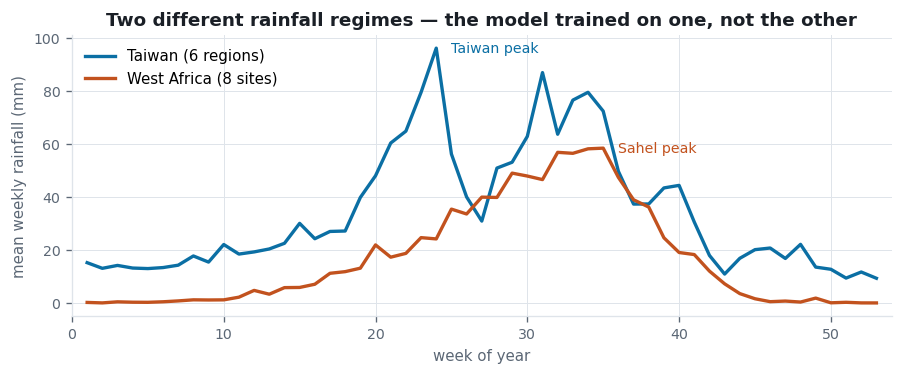

Taiwan   annual mean rainfall:    1875 mm   peak week 24
W Africa annual mean rainfall:     921 mm   peak week 35


In [4]:
tw = pd.read_csv(ROOT/"data"/"processed"/"taiwan_model_table.csv")

tw_wk = tw.groupby("week").rain_mm_lag0.mean()
af_wk = af.groupby("week").rain_mm_lag0.mean()

fig, ax = plt.subplots(figsize=(7.6, 3.2))
ax.plot(tw_wk.index, tw_wk.values, color=C_TW, label="Taiwan (6 regions)")
ax.plot(af_wk.index, af_wk.values, color=C_AF, label="West Africa (8 sites)")
ax.annotate("Taiwan peak", xy=(tw_wk.idxmax(), tw_wk.max()), xytext=(tw_wk.idxmax()+1, tw_wk.max()),
            color=C_TW, fontsize=8.5, va="center")
ax.annotate("Sahel peak", xy=(af_wk.idxmax(), af_wk.max()), xytext=(af_wk.idxmax()+1, af_wk.max()),
            color=C_AF, fontsize=8.5, va="center")
ax.set_xlabel("week of year"); ax.set_ylabel("mean weekly rainfall (mm)")
ax.set_title("Two different rainfall regimes — the model trained on one, not the other")
ax.set_xlim(0,54); ax.legend(loc="upper left"); tidy(ax)
plt.tight_layout(); plt.savefig(OUTD/"fig_rainfall_regimes.png", bbox_inches="tight"); plt.show()

print(f"Taiwan   annual mean rainfall: {tw.rain_mm_lag0.mean()*52:7.0f} mm   peak week {tw_wk.idxmax()}")
print(f"W Africa annual mean rainfall: {af.rain_mm_lag0.mean()*52:7.0f} mm   peak week {af_wk.idxmax()}")

In [5]:
# Feature-by-feature overlap: how much of West Africa sits inside Taiwan's training range?
checks = ["rain_mm_lag0","rain_sum12w","t_mean_lag0","rh_mean_lag0","ws_max_lag0"]
print(f"{'feature':<18}{'Taiwan 5-95%':>22}{'W Africa 5-95%':>22}{'% AF inside TW':>16}")
print("-"*80)
for f in checks:
    lo, hi = tw[f].quantile([0.05,0.95])
    alo, ahi = af[f].quantile([0.05,0.95])
    inside = ((af[f] >= tw[f].min()) & (af[f] <= tw[f].max())).mean()*100
    print(f"{f:<18}{f'{lo:.1f} – {hi:.1f}':>22}{f'{alo:.1f} – {ahi:.1f}':>22}{inside:>15.0f}%")

print("\nA low percentage means the model is extrapolating there, and its output")
print("for those weeks should be read as a guess rather than a prediction.")

feature                     Taiwan 5-95%        W Africa 5-95%  % AF inside TW
--------------------------------------------------------------------------------
rain_mm_lag0                 0.6 – 139.2            0.0 – 68.8            100%
rain_sum12w                 68.4 – 980.7           0.0 – 656.9             70%
t_mean_lag0                  15.1 – 29.1           22.6 – 33.4             85%
rh_mean_lag0                 70.7 – 89.2           16.0 – 84.7             46%
ws_max_lag0                   4.0 – 14.5             4.1 – 9.1            100%

A low percentage means the model is extrapolating there, and its output
for those weeks should be read as a guess rather than a prediction.
